# **Portfolio Forecast Demo: Intraday Sessions and Gaps**

Release 0.4.0 features robust support for intraday forecasting. Each session is a run of *marks*: its open, then each bar's close. The move from one session's close to the next one's open is a return of its own, a *gap*, and the simulators account for the variance discrepancy between gap returns and bar returns.

1. Download a year of hourly bars
2. Backtest a portfolio on them
3. How it works: Converting candlesticks to a `BacktestResult`
4. How it works: Return classes and scaling
5. Read the backtest's performance report
6. Forecast with non-parametric Monte Carlo and read its statistical report
7. Switch to continuous mode for a 24/7 asset

The data window is relative to today, so the numbers in the outputs change from run to run.

## **Imports**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

from portfolio_forecast.forecast import nonparametric_monte_carlo
from portfolio_forecast.performance import performance_report, simulate_buy_and_hold, statistical_report
from portfolio_forecast.plotting import plot_simulated_paths
from portfolio_forecast.utils import close_times

## **Downloading Hourly Bars**

Yahoo Finance can serve hourly bars for the last 730 days. We set `period='1y'`, which gives about 250 sessions. Intraday backtests need the `Open` field since each session's open is a mark ([no opens](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#b15-no-opens)).

In [2]:
# A year of hourly bars for three stocks
tickers = ['AAPL', 'MSFT', 'JPM']
data = yf.download(tickers, period='1y', interval='1h', auto_adjust=True, progress=False)
data['Close'].tail(7)

Ticker,AAPL,JPM,MSFT
Datetime,,,
2026-11-11 09:30:00-05:00,353.540009,341.890015,519.883423
2026-11-11 10:30:00-05:00,354.109985,343.440002,519.810120
2026-11-11 11:30:00-05:00,354.329987,343.250000,521.205017
2026-11-11 12:30:00-05:00,355.049988,344.095001,522.094971
2026-11-11 13:30:00-05:00,354.809906,344.399994,520.729980
2026-11-11 14:30:00-05:00,354.970001,344.355011,519.455017
2026-11-11 15:30:00-05:00,355.790009,343.420013,521.210022


## **Backtesting the Hourly Portfolio**

`simulate_buy_and_hold` buys at the first bar's open and values the portfolio at every mark ([point in time](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#b11-point-in-time), [purchase](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#b2-purchase)). It returns a `BacktestResult` whose `classes` give the class of each return, which the simulators use.

In [3]:
weights = {'AAPL': 0.4, 'MSFT': 0.3, 'JPM': 0.3}
# The portfolio's value at each session's open and each bar's close, starting at 1.0
backtest = simulate_buy_and_hold(data, weights)
backtest.values.tail(9)

/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_85873/3517650695.py:3: UserWarning: 1 session(s) have no bar at the open, first 2026-02-02 13:30:00-05:00: each open mark is the first available bar's open, labelled at its start, and the return into it is irregular
  backtest = simulate_buy_and_hold(data, weights)
/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_85873/3517650695.py:3: UserWarning: 3 return(s) are irregular, first ending 2025-12-01 09:30:00-05:00: a held symbol is stale (no own price) at either end, or a scheduled bar is missing for every symbol. They stay in the values and metrics and are left out of Monte Carlo fits
  backtest = simulate_buy_and_hold(data, weights)


2026-11-10 16:00:00-05:00    1.145837
2026-11-11 09:30:00-05:00    1.148437
2026-11-11 10:30:00-05:00    1.144791
2026-11-11 11:30:00-05:00    1.147046
2026-11-11 12:30:00-05:00    1.148008
2026-11-11 13:30:00-05:00    1.150381
2026-11-11 14:30:00-05:00    1.149517
2026-11-11 15:30:00-05:00    1.148956
2026-11-11 16:00:00-05:00    1.150296
dtype: float64

## **How it works: Converting Candlesticks to a `BacktestResult`**

A `BacktestResult` is a sequence of portfolio snapshots, indexed by a `pd.DatetimeIndex`. It differs from the data type delivered by yfinance since each datetime only has one value associated with it, the accumulated value of the portfolio at that time. Yahoo labels a bar according to start of the period, so its close actually corresponds to a different datetime than the index. The backtest's value at 10:30 is the close of Yahoo's 9:30 bar, not of its 10:30 bar. 

The indices you get from yfinance will not line up with the ones from the `BacktestResult`. This is by design.

In [24]:
# The most recent session with every bar, and its Yahoo labels next to their close labels
bar_days = pd.Series(data.index.date, index=data.index)
days = bar_days.value_counts().loc[lambda counts: counts == counts.max()].index
starts = data.index[(bar_days == days[0]) | (bar_days == days[1])]
pd.DataFrame({'Yahoo label (bar start)': starts, 'Close label': close_times(starts)})

,Yahoo label (bar start),Close label
0,2025-11-12 09:30:00-05:00,2025-11-12 10:30:00-05:00
1,2025-11-12 10:30:00-05:00,2025-11-12 11:30:00-05:00
2,2025-11-12 11:30:00-05:00,2025-11-12 12:30:00-05:00
3,2025-11-12 12:30:00-05:00,2025-11-12 13:30:00-05:00
4,2025-11-12 13:30:00-05:00,2025-11-12 14:30:00-05:00
5,2025-11-12 14:30:00-05:00,2025-11-12 15:30:00-05:00
6,2025-11-12 15:30:00-05:00,2025-11-12 16:00:00-05:00
7,2025-11-13 09:30:00-05:00,2025-11-13 10:30:00-05:00
8,2025-11-13 10:30:00-05:00,2025-11-13 11:30:00-05:00
9,2025-11-13 11:30:00-05:00,2025-11-13 12:30:00-05:00


The same session in the backtest has one more mark than it has bars: the open mark first, then each bar's close.

- The open mark ends the **gap**, the return from the previous session's last close to this open ([gap](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#b14-gap)). Its clock length is a whole night, or a weekend, but a gap is always one unit ([units](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#u2-units)).
- The first bar runs from the open to its close ([first bar](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#b12-first-bar)); later bars run close to close ([later bars](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#b13-later-bars)).
- Each bar's length is shown as $\rho = \tau/\Delta$, its clock length over the bar size, $\Delta$, which is one hour in this case. In general, the last bar of an hourly session has $\rho = 0.5$ since it's only 30 minutes.

<br>
<img src="images/session_marks.png" alt="One session of hourly bars: one gap, seven bars and eight marks" width="1000">

In [5]:
# The session's marks: value, class of the return ending there, clock length and rho = tau / Delta
bar_size = pd.Timedelta(hours=1)
mark_days = pd.Series(backtest.dates.date, index=backtest.dates)
marks = backtest.values[mark_days == day]
clock_length = backtest.dates.to_series().diff()[marks.index]
classes = backtest.classes.reindex(marks.index)
pd.DataFrame({
    'Value': marks,
    'Class': classes,
    'Clock length': clock_length,
    'rho': np.where(classes == 'gap', 1.0, clock_length / bar_size),
})

,Value,Class,Clock length,rho
2026-11-11 09:30:00-05:00,1.148437,gap,0 days 17:30:00,1.0
2026-11-11 10:30:00-05:00,1.144791,regular,0 days 01:00:00,1.0
2026-11-11 11:30:00-05:00,1.147046,regular,0 days 01:00:00,1.0
2026-11-11 12:30:00-05:00,1.148008,regular,0 days 01:00:00,1.0
2026-11-11 13:30:00-05:00,1.150381,regular,0 days 01:00:00,1.0
2026-11-11 14:30:00-05:00,1.149517,regular,0 days 01:00:00,1.0
2026-11-11 15:30:00-05:00,1.148956,regular,0 days 01:00:00,1.0
2026-11-11 16:00:00-05:00,1.150296,regular,0 days 00:30:00,0.5


## **How it works: Return Classes**

Every return has a class ([classes](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#u1-classes), [Return classes](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#return-classes)): `gap`, `regular`, or `irregular`. Each Monte Carlo simulation draws returns according to their class instead of from one pooled sample or distribution.

In [6]:
# How many returns of each class the backtest has
backtest.classes.value_counts()

regular      1739
gap           247
irregular       4
Name: count, dtype: int64

| Class | Return | Used by the simulators |
| --- | --- | --- |
| `gap` | From a session's last close to the next session's open (intraday only) | Drawn for future open marks |
| `regular` | Return accumulated across a single bar | Drawn for future bar closes |
| `irregular` | A held symbol is stale at either end, the session's first bar is missing, or the return spans a missing scheduled bar or session | Never drawn; kept in the values and the reports |

The warnings printed by the backtest above count the irregular returns.

### **Scaling `regular` Returns**

The `regular` returns are measured per full bar. For a bar covering a fraction $\rho$ of a full trading hour, the mean and volatility scale differently:

$$\mu_\rho = \rho\,\mu, \qquad \sigma_\rho = \sqrt{\rho}\,\sigma$$

Here $\ell = \ln(1 + r)$ is a bar's log return, with $r$ its ordinary return, and $\mu$ and $\sigma$ are the mean and volatility of the log return per full bar, estimated from all the `regular` returns. This scaling assumes that log returns follow a random walk with drift during trading hours.

1. Learning from history: Scale short-bar returns up to full-bar equivalents before combining them with other `regular` returns:

$$\ell_{\text{full}} = \mu + \frac{\ell_\rho - \rho\,\mu}{\sqrt{\rho}}$$

2. Simulating the future: Scale full-bar returns down to match the duration of the simulated bar:

$$\ell_\rho = \rho\,\mu + \sqrt{\rho}\,(\ell_{\text{full}} - \mu)$$

For example, a half-hour bar ($\rho = 0.5$) has half the expected return and approximately 71% of the volatility of a full-hour bar ([the full explanation](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#what-all-three-share)).

Only `regular` returns are scaled. `gap` returns always count as one full unit, regardless of whether they span a night or a weekend ([units](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#u2-units)). Full bars ($\rho = 1$) are unchanged.

## **Backtest Performance Report**

`performance_report` summarizes the historical performance of this portfolio. Some risk figures are calculated at the session level, on session returns. A session return is one session's gap and bars rolled into a single close-to-close return. This is important to know when reading these figures on intraday data. The metrics can be interpreted as follows:

- **Volatility**: the standard deviation of the session returns, not of the hourly bar returns, annualized. It is the figure daily data would give.
- **Downside Vol**: the same idea, but only sessions that fall short of the risk-free rate (zero by default) add to it. The shortfalls are averaged over every session, not just the losing ones.
- **Gap Vol (per gap)**: the standard deviation of the gap returns. It is per gap and not annualized, so it can't be compared with Volatility. A weekend is one gap, the same as a single night.
- **Bar Vol (per bar)**: the standard deviation of the bar returns, per full bar (one hour here) and not annualized. A short bar is scaled up to a full bar before it is counted. Gap Vol and Bar Vol both leave out irregular returns ([per-class volatility](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#m5-per-class-volatility)).
- **Max Drawdown**: the largest fall from an earlier high, as a fraction of that high. It is the one risk figure measured on every mark, not on session closes, so a fall inside a session or at an open counts ([max drawdown](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#m6-max-drawdown)).
- **Sharpe Ratio**: the average session return above the risk-free rate, divided by the standard deviation of the session returns, annualized. Because it uses session returns, it does not change with the bar size.
- **Sortino Ratio**: the Sharpe ratio with the shortfall measure from Downside Vol in place of the standard deviation, so only shortfalls count as risk.

As with demo 1, the performance report takes either a `BacktestResult` (recommended, since it carries the return classes) or a pandas `Series` as input.

In [7]:
# The history's report
history = performance_report(backtest, display=True)


            PORTFOLIO PERFORMANCE REPORT            
----------------------------------------------------
  Total Time         :  1.00 years (364 days)
  Periods            :  1990 returns
                      RETURNS                       
----------------------------------------------------
  Initial Bankroll   :         1.00
  Final Bankroll     :         1.15
  Total Return       :       15.03%
  CAGR               :       15.09%
----------------------------------------------------
  Actual Yearly Returns:
    - 2025            :       -1.39%  (50 days)
    - 2026            :       16.65%  (314 days)
                        RISK                        
----------------------------------------------------
  Volatility         :       17.82%
  Downside Vol       :       11.80%
  Gap Vol (per gap)  :        0.73%
  Bar Vol (per bar)  :        0.36%
  Max Drawdown       :       16.71%
  Sharpe Ratio       :         0.86
  Sortino Ratio      :         1.30



## **Non-Parametric Forecast and Statistical Report**

`nonparametric_monte_carlo` fits no distribution. Each future open draws one of the history's gaps, and each future bar draws one of its regular bars. Each class needs at least 30 returns in the history. On intraday history `sim_length` counts sessions, not bars, which the warning below confirms.

Similar to `performance_report`, all of the Monte Carlo simulators work best when given a `BacktestResult` for the values argument; however, they still work with a `Series` or array-like object.

In [8]:
# The horizon in sessions (63 is about three months) and the number of simulated paths
horizon, n_paths = 63, 1000

sims = nonparametric_monte_carlo(backtest, sim_length=horizon, n_sims=n_paths, random_state=np.random.default_rng(42))

# How many future marks of each class the forecast has
pd.Series(sims.classes).value_counts()

/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_85873/3410373280.py:4: UserWarning: nonparametric_monte_carlo: on intraday history sim_length counts sessions, not bars (changed in 0.4.0): sim_length=63 gives 498 future marks, ending at the close of the last of 63 sessions. For a daily forecast, pass to_session_values(values)
  sims = nonparametric_monte_carlo(backtest, sim_length=horizon, n_sims=n_paths, random_state=np.random.default_rng(42))


regular    435
gap         63
Name: count, dtype: int64

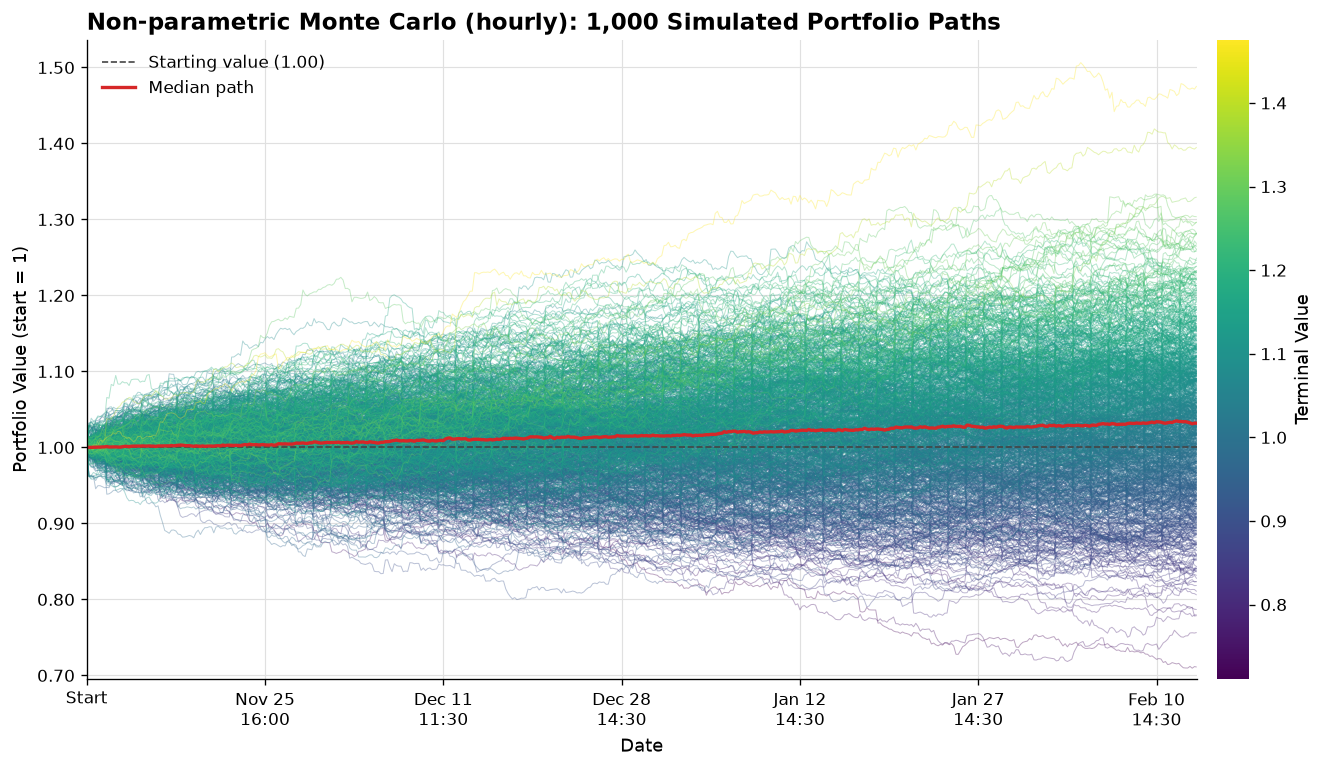

In [9]:
# Fan chart of the hourly paths
fig, ax = plot_simulated_paths(sims, method='Non-parametric Monte Carlo (hourly)')
plt.show()

Over a three-month horizon CAGR is an annualized figure from a short window, so Total Return is the one to read.

In [10]:
# Each figure's mean, median and 95% range across the paths
report = statistical_report(sims, display=True)


                     SIMULATED PORTFOLIO STATISTICAL REPORT                     
--------------------------------------------------------------------------------
  Simulated Paths      : 1,000
  Total Time           :  0.25 years (93 days)
  Horizon              :   498 periods
                                    RETURNS                                     
--------------------------------------------------------------------------------
                               Mean       Median         95% range across paths
--------------------------------------------------------------------------------
  Final Bankroll       :       1.03         1.03                   [0.86, 1.23]
  Total Return         :      3.43%        3.19%              [-14.47%, 23.09%]
  CAGR                 :     20.65%       13.39%             [-46.48%, 129.54%]
                                      RISK                                      
----------------------------------------------------------------------------

## **Continuous Mode for a 24/7 Asset**

Bitcoin trades around the clock, so it has no sessions, opens or gaps. `calendar=None` is continuous mode ([continuous mode](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#u3-continuous-mode), [Calendars](https://github.com/YohoCodes/portfolio-forecast/blob/v0.4.0/README.md#concepts)). The bars form a constant hourly grid, every return is regular (or irregular where a grid point is missing), and the future marks run every hour, weekends included. Risk figures use calendar-day returns at 00:00 UTC, annualized with 365, and CAGR needs the calendar clock, `cagr_clock='calendar'`.

In [11]:
# A year of hourly BTC-USD bars, backtested without a calendar
btc = yf.download('BTC-USD', period='1y', interval='1h', auto_adjust=True, progress=False)
btc_backtest = simulate_buy_and_hold(btc, {'BTC-USD': 1.0}, calendar=None)
btc_backtest.classes.value_counts()

/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_85873/979183419.py:3: UserWarning: 2 return(s) are irregular, first ending 2025-11-29 20:00:00+00:00: a held symbol is stale (no own price) at either end, or a scheduled bar is missing for every symbol. They stay in the values and metrics and are left out of Monte Carlo fits
  btc_backtest = simulate_buy_and_hold(btc, {'BTC-USD': 1.0}, calendar=None)


regular      8737
irregular       2
Name: count, dtype: int64

In [12]:
# The history's report on the calendar clock
btc_history = performance_report(btc_backtest, calendar=None, cagr_clock='calendar', display=True)


            PORTFOLIO PERFORMANCE REPORT            
----------------------------------------------------
  Total Time         :  1.00 years (365 days)
  Periods            :  8739 returns
                      RETURNS                       
----------------------------------------------------
  Initial Bankroll   :         1.00
  Final Bankroll     :         0.72
  Total Return       :      -27.65%
  CAGR               :      -27.67%
----------------------------------------------------
  Actual Yearly Returns:
    - 2025            :      -14.79%  (51 days)
    - 2026            :      -15.09%  (315 days)
                        RISK                        
----------------------------------------------------
  Volatility         :       44.24%
  Downside Vol       :       31.22%
  Bar Vol (per bar)  :        0.46%
  Max Drawdown       :       44.72%
  Sharpe Ratio       :        -0.54
  Sortino Ratio      :        -0.76



In continuous mode `sim_length` counts bars, so 63 days ahead is `horizon * 24` hourly marks, with no step skipped over the weekend. The risk figures use one return per calendar day, so a horizon of only a few days gives them too few returns to mean anything.

In [13]:
# 63 days of hourly marks ahead
btc_sims = nonparametric_monte_carlo(btc_backtest, sim_length=horizon * 24, n_sims=n_paths, calendar=None,
                                     random_state=np.random.default_rng(42))
pd.Series(btc_sims.classes).value_counts()

regular    1512
Name: count, dtype: int64

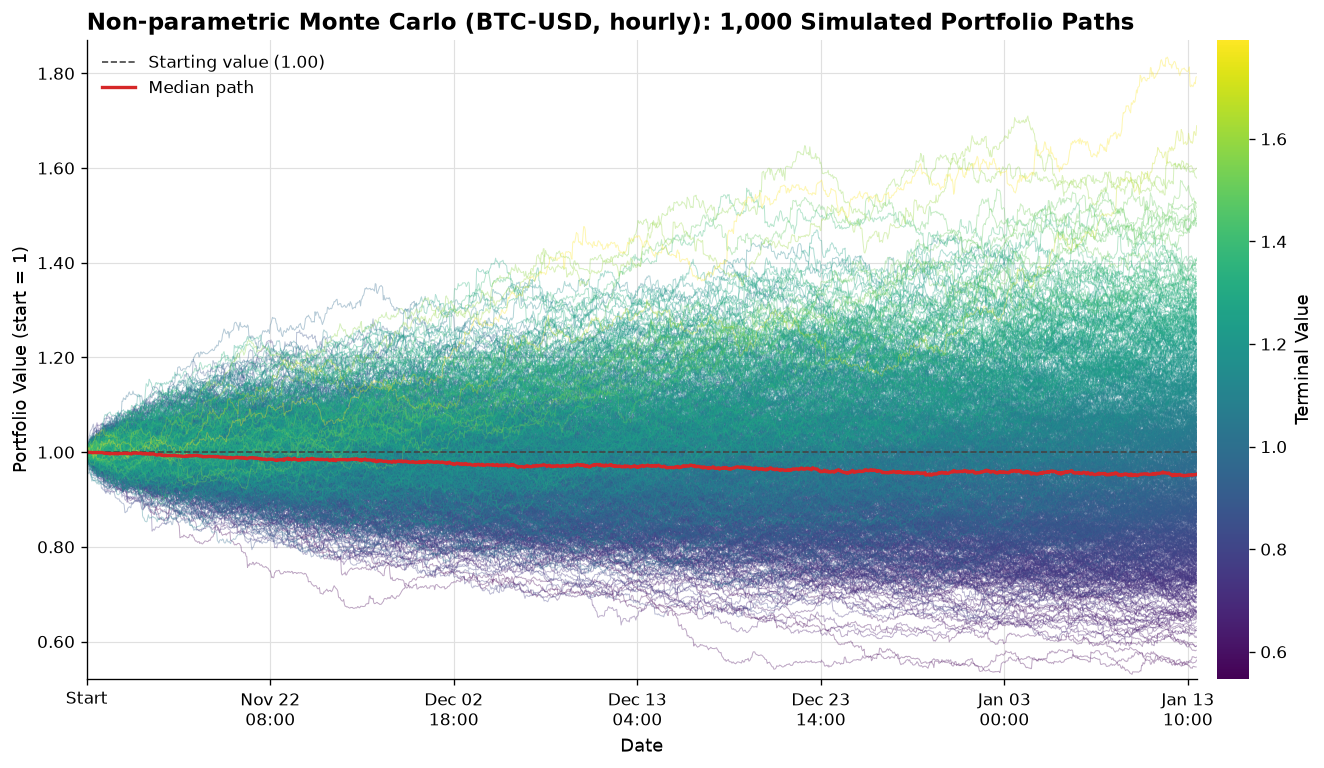


                     SIMULATED PORTFOLIO STATISTICAL REPORT                     
--------------------------------------------------------------------------------
  Simulated Paths      : 1,000
  Total Time           :  0.17 years (63 days)
  Horizon              :  1512 periods
                                    RETURNS                                     
--------------------------------------------------------------------------------
                               Mean       Median         95% range across paths
--------------------------------------------------------------------------------
  Final Bankroll       :       0.97         0.95                   [0.67, 1.35]
  Total Return         :     -3.31%       -4.67%              [-33.34%, 34.55%]
  CAGR                 :     31.03%      -24.20%             [-90.47%, 458.80%]
                                      RISK                                      
----------------------------------------------------------------------------

In [14]:
# The forecast's fan chart and report, on the calendar clock
fig, ax = plot_simulated_paths(btc_sims, method='Non-parametric Monte Carlo (BTC-USD, hourly)')
plt.show()
btc_report = statistical_report(btc_sims, calendar=None, cagr_clock='calendar', display=True)